# 05 Machine learning: what goes with higher PM2.5?

Builds a table of area characteristics for every upazila, then asks two questions with random forest and XGBoost:
1. Which characteristics go with higher exposure today (the last five years)?
2. Which go with a bigger rise since the first five years?

**Why spatial cross-validation:** neighbouring upazilas have almost the same air. With ordinary random folds, the model is tested on upazilas whose neighbours it trained on, so it looks better than it is. Spatial folds hold out whole regions at a time, which is the honest test of whether the model has learned something that carries over to a new place. Both are reported side by side; the gap between them is a finding in itself.

**Covariates** (all open, no account needed)

| Covariate | Why it might matter | Source |
| --- | --- | --- |
| Population density (log) | More people, more traffic, cooking and burning | WorldPop 2022 (already downloaded) |
| Urban share | Share of people living in 1 km cells with at least 1,500 people per km² (the usual urban-centre density) | WorldPop 2022 |
| Distance to Dhaka | The Dhaka region holds the most brick kilns, industry and traffic | computed |
| Elevation | Low, flat land traps air; hills and the north-east are cleaner | Copernicus 90 m DEM on AWS |
| Major road density | Traffic emissions | OpenStreetMap (Geofabrik) |
| Dry-season wind speed | Wind disperses pollution in the worst months | NASA POWER climatology |
| Annual rainfall | Rain washes particles out | NASA POWER climatology |

Each download is wrapped so that if one source fails, the notebook carries on with the others and says which one was skipped.

**What this is not:** these are area-level associations, not causes. Brick kilns, crop burning and transboundary smoke from India are major sources that have no open, consistent map, so their effect sits partly inside "distance to Dhaka" and partly in what the model cannot explain.

**Outputs:** `data/processed/upazila_covariates.parquet` (also used by the spatial regression in R), `outputs/models/` (cross-validation results, out-of-fold predictions, SHAP values), figures in `outputs/figures/`

In [1]:
%pip install -q rioxarray shap pyogrio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 20.4 MB/s eta 0:00:00


In [2]:
import pandas as pd, numpy as np, xarray as xr, geopandas as gpd, rioxarray, pyogrio, rasterio.features, requests, pathlib, tempfile, shutil, time
import matplotlib.pyplot as plt, shap
from rasterio.transform import from_origin
from sklearn.model_selection import KFold, GroupKFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from xgboost import XGBRegressor
from tqdm.auto import tqdm

try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = pathlib.Path("/content/drive/MyDrive/Bangladesh Air Pollution Project")
except ImportError:
    ROOT = pathlib.Path.cwd().parent

PROC, COV, FIG, MOD = ROOT / "data" / "processed", ROOT / "data" / "raw" / "covariates", ROOT / "outputs" / "figures", ROOT / "outputs" / "models"
for d in (COV, FIG, MOD):
    d.mkdir(parents=True, exist_ok=True)
TMP = pathlib.Path(tempfile.gettempdir()) / "cov_tmp"
TMP.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
PLUM, SEED = "#6b2d5c", 42

upazila = gpd.read_file(PROC / "bgd_admin.gpkg", layer="upazila")
uy = pd.read_parquet(PROC / "pm25_unit_year.parquet").query("level == 'upazila'")
grid = xr.open_dataset(PROC / "pm25_annual_grid.nc").load()
YEARS = sorted(uy["year"].unique())
mean_over = lambda yrs: uy[uy["year"].isin(yrs)].groupby("pcode")["pm25_popw"].mean()
utm = upazila.to_crs(32646)
df = pd.DataFrame({"pcode": upazila["pcode"], "name": upazila["name"], "district_pcode": upazila["district_pcode"], "division_pcode": upazila["division_pcode"],
                   "area_km2": upazila["area_km2"], "x_km": utm.centroid.x / 1000, "y_km": utm.centroid.y / 1000,
                   "lon": upazila.to_crs(4326).representative_point().x, "lat": upazila.to_crs(4326).representative_point().y})
df["pm25_recent"] = df["pcode"].map(mean_over(YEARS[-5:]))
df["pm25_change"] = df["pm25_recent"] - df["pcode"].map(mean_over(YEARS[:5]))
status = []
print(f"{len(df)} upazilas | recent = {YEARS[-5]}-{YEARS[-1]} mean, change = recent minus {YEARS[0]}-{YEARS[4]} mean")

Mounted at /content/drive
507 upazilas | recent = 2020-2024 mean, change = recent minus 1998-2002 mean


## 1. Covariates from data already downloaded

Population density and urban share come from the 2022 population on the 0.01° grid (notebook 02). Each 0.01° cell is assigned to the upazila its centre falls in, as in notebook 02. Distance to Dhaka is measured from each upazila's centre to central Dhaka in a metric projection (UTM 46N).

In [3]:
dx, dy = float(grid["lon"][1] - grid["lon"][0]), float(grid["lat"][1] - grid["lat"][0])
zone = np.flipud(rasterio.features.rasterize(zip(upazila.geometry, range(len(upazila))), out_shape=(grid.sizes["lat"], grid.sizes["lon"]),
                 transform=from_origin(float(grid["lon"][0]) - dx / 2, float(grid["lat"][-1]) + dy / 2, dx, dy), fill=-1, dtype="int32")).ravel()
inside = zone >= 0
cell_km2 = (111.32 * dx * np.cos(np.radians(grid["lat"].values))[:, None] * 110.57 * dy * np.ones((1, grid.sizes["lon"]))).ravel()
pop = grid["pop_2022"].values.ravel()
urban = (pop / cell_km2) >= 1500
people = np.bincount(zone[inside], pop[inside], len(upazila))
df["log_pop_density"] = np.log10(people / df["area_km2"] + 1)
df["urban_share"] = np.bincount(zone[inside], (pop * urban)[inside], len(upazila)) / np.where(people > 0, people, np.nan)
dhaka = gpd.GeoSeries(gpd.points_from_xy([90.4125], [23.8103]), crs=4326).to_crs(32646).iloc[0]
df["dist_dhaka_km"] = np.hypot(df["x_km"] - dhaka.x / 1000, df["y_km"] - dhaka.y / 1000)
status.append({"covariate": "log_pop_density, urban_share, dist_dhaka_km", "source": "WorldPop / computed", "status": "ok"})
df[["log_pop_density", "urban_share", "dist_dhaka_km"]].describe().round(2).T

,count,mean,std,min,25%,50%,75%,max
log_pop_density,507.0,3.03,0.34,1.49,2.92,3.04,3.18,4.35
urban_share,507.0,0.51,0.27,0.00,0.30,0.49,0.74,1.00
dist_dhaka_km,507.0,150.40,73.98,1.33,95.00,143.40,196.23,366.44


## 2. Elevation (Copernicus 90 m DEM)

The 1° × 1° Copernicus GLO-90 tiles covering Bangladesh are read straight from the public AWS bucket. Each tile is averaged into 0.01° blocks (12 × 12 pixels) so it lines up with the PM2.5 grid, then averaged per upazila. Tiles that are all sea do not exist in the bucket and are skipped.

In [4]:
def dem_tile(lat, lon):
    name = f"Copernicus_DSM_COG_30_N{lat:02d}_00_E{lon:03d}_00_DEM"
    da = rioxarray.open_rasterio(f"https://copernicus-dem-90m.s3.amazonaws.com/{name}/{name}.tif", masked=True).squeeze(drop=True)
    da = da.coarsen(x=12, y=12, boundary="trim").mean()
    return pd.DataFrame({"lat": np.repeat(da["y"].values, da.sizes["x"]), "lon": np.tile(da["x"].values, da.sizes["y"]), "elev": da.values.ravel()})

try:
    tiles = []
    for la in tqdm(range(20, 27), desc="DEM rows"):
        for lo in range(88, 93):
            try:
                tiles.append(dem_tile(la, lo))
            except Exception:
                pass
    dem = pd.concat(tiles)
    i = np.rint((dem["lat"].values - float(grid["lat"][0])) / dy).astype(int)
    j = np.rint((dem["lon"].values - float(grid["lon"][0])) / dx).astype(int)
    ok = (i >= 0) & (i < grid.sizes["lat"]) & (j >= 0) & (j < grid.sizes["lon"]) & ~np.isnan(dem["elev"].values)
    elev = np.full(grid.sizes["lat"] * grid.sizes["lon"], np.nan)
    elev[i[ok] * grid.sizes["lon"] + j[ok]] = dem["elev"].values[ok]
    has = inside & ~np.isnan(elev)
    df["elevation_m"] = np.bincount(zone[has], elev[has], len(upazila)) / np.where(np.bincount(zone[has], minlength=len(upazila)) > 0, np.bincount(zone[has], minlength=len(upazila)), np.nan)
    status.append({"covariate": "elevation_m", "source": "Copernicus GLO-90", "status": f"ok, {len(tiles)} tiles, {df['elevation_m'].isna().sum()} upazilas missing"})
except Exception as e:
    status.append({"covariate": "elevation_m", "source": "Copernicus GLO-90", "status": f"skipped: {e}"})
status[-1]

DEM rows:   0%|          | 0/7 [00:00<?, ?it/s]

{'covariate': 'elevation_m',
 'source': 'Copernicus GLO-90',
 'status': 'ok, 31 tiles, 0 upazilas missing'}

## 3. Major road density (OpenStreetMap)

The Bangladesh OpenStreetMap extract from Geofabrik (about 340 MB) is downloaded to the temporary disk, and only major roads are read: motorway, trunk, primary and secondary (with their link roads). Road length inside each upazila is divided by its area to give km of major road per km². Reading the file takes a few minutes. The large file is deleted afterwards; only the per-upazila numbers are kept.

In [5]:
MAJOR = ("motorway", "motorway_link", "trunk", "trunk_link", "primary", "primary_link", "secondary", "secondary_link")
try:
    pbf = TMP / "bangladesh-latest.osm.pbf"
    if not pbf.exists():
        with requests.get("https://download.geofabrik.de/asia/bangladesh-latest.osm.pbf", stream=True, timeout=600) as r, open(pbf, "wb") as f:
            r.raise_for_status(); [f.write(ch) for ch in r.iter_content(1 << 22)]
    roads = pyogrio.read_dataframe(pbf, layer="lines", columns=["highway"], where=f"highway IN {MAJOR}").to_crs(32646)
    pieces = gpd.overlay(roads[["geometry"]], utm[["pcode", "geometry"]], how="intersection", keep_geom_type=True)
    df["road_km_per_km2"] = df["pcode"].map(pieces.assign(km=pieces.length / 1000).groupby("pcode")["km"].sum()).fillna(0) / df["area_km2"]
    pbf.unlink()
    status.append({"covariate": "road_km_per_km2", "source": "OpenStreetMap", "status": f"ok, {len(roads):,} major road segments"})
except Exception as e:
    status.append({"covariate": "road_km_per_km2", "source": "OpenStreetMap", "status": f"skipped: {e}"})
status[-1]

{'covariate': 'road_km_per_km2',
 'source': 'OpenStreetMap',
 'status': 'ok, 17,746 major road segments'}

## 4. Dry-season wind and rainfall (NASA POWER)

NASA POWER gives long-term monthly averages from a global reanalysis on a grid of about 0.5°. One request per 0.5° cell that holds an upazila centre (about 60 to 80 requests, with a short pause between them). Kept per upazila:
- `dry_wind_ms`: mean 2 m wind speed in December to February, the worst months for PM2.5
- `rain_mm_day`: annual mean rainfall

In [6]:
try:
    df["cell"] = list(zip((df["lat"] * 2).round() / 2, (df["lon"] * 2).round() / 2))
    clim = {}
    for la, lo in tqdm(sorted(df["cell"].unique()), desc="POWER cells"):
        r = requests.get("https://power.larc.nasa.gov/api/temporal/climatology/point", params={"parameters": "WS2M,PRECTOTCORR", "community": "RE", "latitude": la, "longitude": lo, "format": "JSON"}, timeout=60)
        r.raise_for_status()
        p = r.json()["properties"]["parameter"]
        clim[(la, lo)] = {"dry_wind_ms": np.mean([p["WS2M"][m] for m in ("DEC", "JAN", "FEB")]), "rain_mm_day": p["PRECTOTCORR"]["ANN"]}
        time.sleep(0.5)
    df = df.join(df["cell"].map(clim).apply(pd.Series))
    status.append({"covariate": "dry_wind_ms, rain_mm_day", "source": "NASA POWER", "status": f"ok, {len(clim)} cells"})
except Exception as e:
    status.append({"covariate": "dry_wind_ms, rain_mm_day", "source": "NASA POWER", "status": f"skipped: {e}"})
df = df.drop(columns="cell", errors="ignore")
shutil.rmtree(TMP, ignore_errors=True)
pd.DataFrame(status)

POWER cells:   0%|          | 0/69 [00:00<?, ?it/s]

,covariate,source,status
0,"log_pop_density, urban_share, dist_dhaka_km",WorldPop / computed,ok
1,elevation_m,Copernicus GLO-90,"ok, 31 tiles, 0 upazilas missing"
2,road_km_per_km2,OpenStreetMap,"ok, 17,746 major road segments"
3,"dry_wind_ms, rain_mm_day",NASA POWER,"ok, 69 cells"


Using: ['log_pop_density', 'urban_share', 'dist_dhaka_km', 'elevation_m', 'road_km_per_km2', 'dry_wind_ms', 'rain_mm_day'] | skipped: none
Values filled with the median: none


,pm25_recent,pm25_change
dist_dhaka_km,-0.67,-0.40
elevation_m,-0.39,-0.08
rain_mm_day,-0.31,-0.53
dry_wind_ms,0.29,-0.00
urban_share,0.31,0.22
road_km_per_km2,0.32,0.29
log_pop_density,0.41,0.29


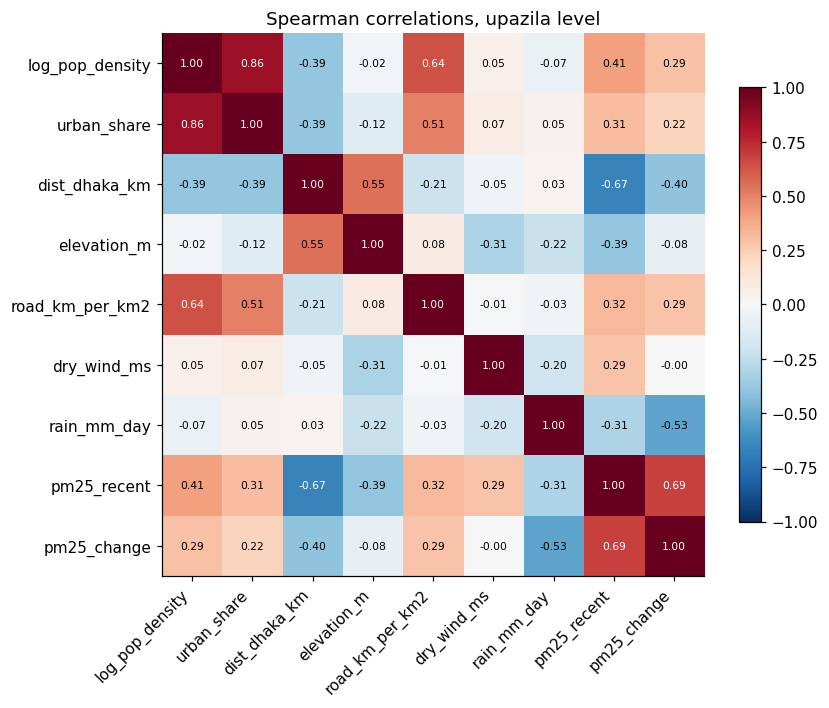

In [7]:
CANDIDATES = ["log_pop_density", "urban_share", "dist_dhaka_km", "elevation_m", "road_km_per_km2", "dry_wind_ms", "rain_mm_day"]
FEATURES = [c for c in CANDIDATES if c in df and df[c].notna().mean() > 0.9]
print("Using:", FEATURES, "| skipped:", sorted(set(CANDIDATES) - set(FEATURES)) or "none")
print("Values filled with the median:", df[FEATURES].isna().sum()[lambda s: s > 0].to_dict() or "none")
df[FEATURES] = df[FEATURES].fillna(df[FEATURES].median())
df.to_parquet(PROC / "upazila_covariates.parquet", index=False)
rho = df[FEATURES + ["pm25_recent", "pm25_change"]].corr("spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
im = ax.imshow(rho, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set(xticks=range(len(rho)), yticks=range(len(rho)), xticklabels=rho.columns, yticklabels=rho.columns, title="Spearman correlations, upazila level")
plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
for (a, b), v in np.ndenumerate(rho.values):
    ax.text(b, a, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else "black")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.savefig(FIG / "05_correlations.png", dpi=200, bbox_inches="tight")
rho.loc[FEATURES, ["pm25_recent", "pm25_change"]].round(2).sort_values("pm25_recent")

## 5. Random vs spatial cross-validation

Three models, each scored on predictions for upazilas it did not see:
- **Linear regression** on standardised covariates, the simple baseline
- **Random forest**, 500 trees
- **XGBoost**, shallow trees with a small learning rate

**Folds:** random 10-fold, and spatial 10-fold where upazilas are grouped into 10 regions by k-means on their centre coordinates and a whole region is held out at a time. The fold map below shows the regions.

In [8]:
regions = KMeans(n_clusters=10, n_init=10, random_state=SEED).fit_predict(df[["x_km", "y_km"]])
schemes = {"random": (KFold(10, shuffle=True, random_state=SEED), None), "spatial": (GroupKFold(10), regions)}
models = {"Linear regression": make_pipeline(StandardScaler(), LinearRegression()),
          "Random forest": RandomForestRegressor(n_estimators=500, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
          "XGBoost": XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=4, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1)}
X = df[FEATURES]
rows, oof = [], df[["pcode", "name", "pm25_recent", "pm25_change"]].assign(region=regions)
for target in ("pm25_recent", "pm25_change"):
    for scheme, (cv, groups) in schemes.items():
        for mname, model in tqdm(models.items(), desc=f"{target}, {scheme}", leave=False):
            pred = cross_val_predict(model, X, df[target], cv=cv, groups=groups)
            oof[f"{target}|{scheme}|{mname}"] = pred
            rows.append({"target": target, "cv": scheme, "model": mname, "R2": r2_score(df[target], pred), "MAE": mean_absolute_error(df[target], pred), "RMSE": mean_squared_error(df[target], pred) ** 0.5})
cv_results = pd.DataFrame(rows).round(3)
cv_results.to_csv(MOD / "05_cv_results.csv", index=False)
oof.to_parquet(MOD / "05_oof_predictions.parquet", index=False)
cv_results.pivot_table(index=["target", "model"], columns="cv", values=["R2", "MAE"]).round(3)

pm25_recent, random:   0%|          | 0/3 [00:00<?, ?it/s]

pm25_recent, spatial:   0%|          | 0/3 [00:00<?, ?it/s]

pm25_change, random:   0%|          | 0/3 [00:00<?, ?it/s]

pm25_change, spatial:   0%|          | 0/3 [00:00<?, ?it/s]

MAE             R2        
cv                            random spatial random spatial
target      model                                          
pm25_change Linear regression  2.181   2.776  0.586   0.356
            Random forest      1.346   2.594  0.816   0.347
            XGBoost            1.308   2.490  0.834   0.404
pm25_recent Linear regression  5.561   7.813  0.640   0.279
            Random forest      2.292   5.238  0.925   0.619
            XGBoost            2.025   4.713  0.938   0.660

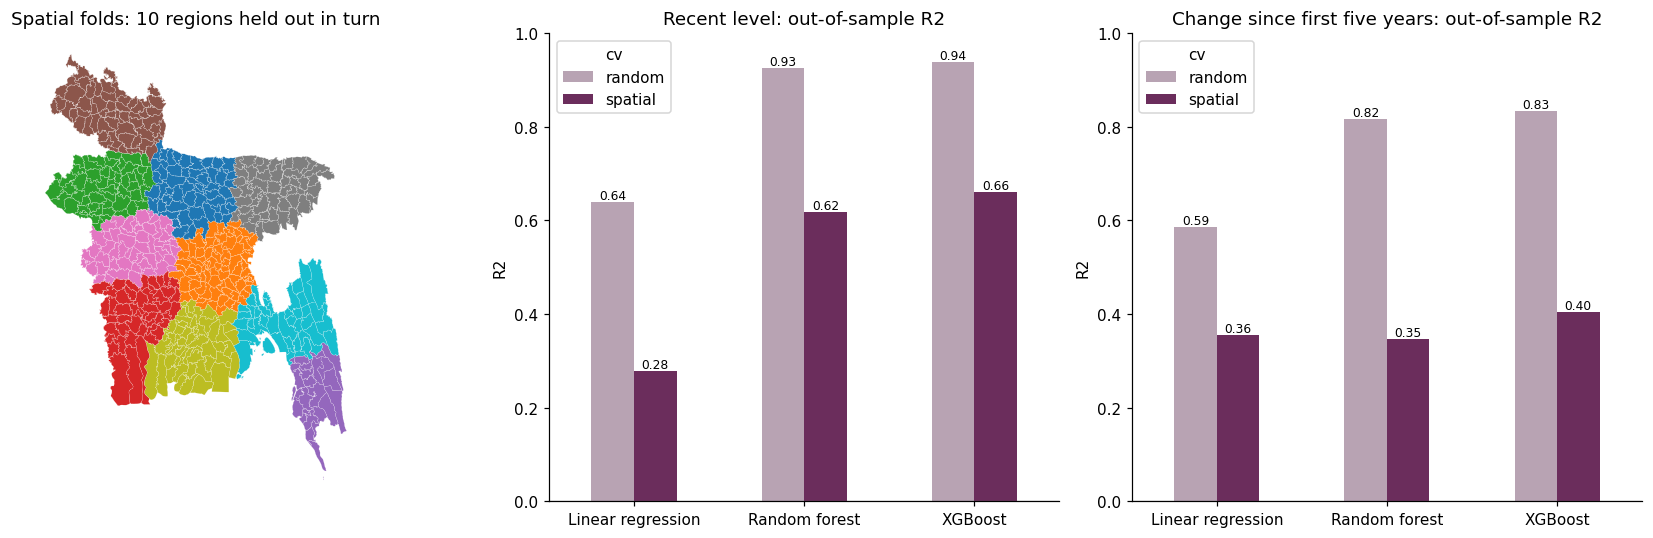

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5), gridspec_kw={"width_ratios": [1.1, 1, 1]})
upazila.assign(region=regions).plot(column="region", cmap="tab10", ax=ax[0], edgecolor="white", linewidth=0.1)
ax[0].set_title("Spatial folds: 10 regions held out in turn"); ax[0].set_axis_off()
for a, target, title in zip(ax[1:], ("pm25_recent", "pm25_change"), ("Recent level", "Change since first five years")):
    t = cv_results.query("target == @target").pivot(index="model", columns="cv", values="R2")[["random", "spatial"]]
    t.plot.bar(ax=a, color=["#b8a3b3", PLUM], rot=0)
    a.set(title=f"{title}: out-of-sample R2", ylabel="R2", xlabel="", ylim=(min(0, t.values.min() - 0.05), 1)); a.axhline(0, color="grey", lw=0.8)
    for c in a.containers:
        a.bar_label(c, fmt="%.2f", fontsize=8)
plt.tight_layout(); plt.savefig(FIG / "05_cv_random_vs_spatial.png", dpi=200, bbox_inches="tight")

**How to read this:** the random-fold scores show how well the models fill gaps between known upazilas. The spatial-fold scores show how well they predict a region they have never seen. A large drop from random to spatial means much of the apparent skill came from neighbours looking alike, not from the covariates. The spatial score is the one to quote.

## 6. What drives the model (SHAP)

XGBoost is refitted on all upazilas for the recent level and explained with SHAP values. Each dot is one upazila: its position shows how much that covariate pushed the prediction up or down from the average, and its colour shows whether the covariate value was high or low there. These explain the model, so they inherit its limits: correlated covariates (for example density and urban share) share credit between them.

,mean_abs_shap
dist_dhaka_km,3.94
rain_mm_day,3.11
dry_wind_ms,3.03
elevation_m,1.48
log_pop_density,0.47
urban_share,0.46
road_km_per_km2,0.37


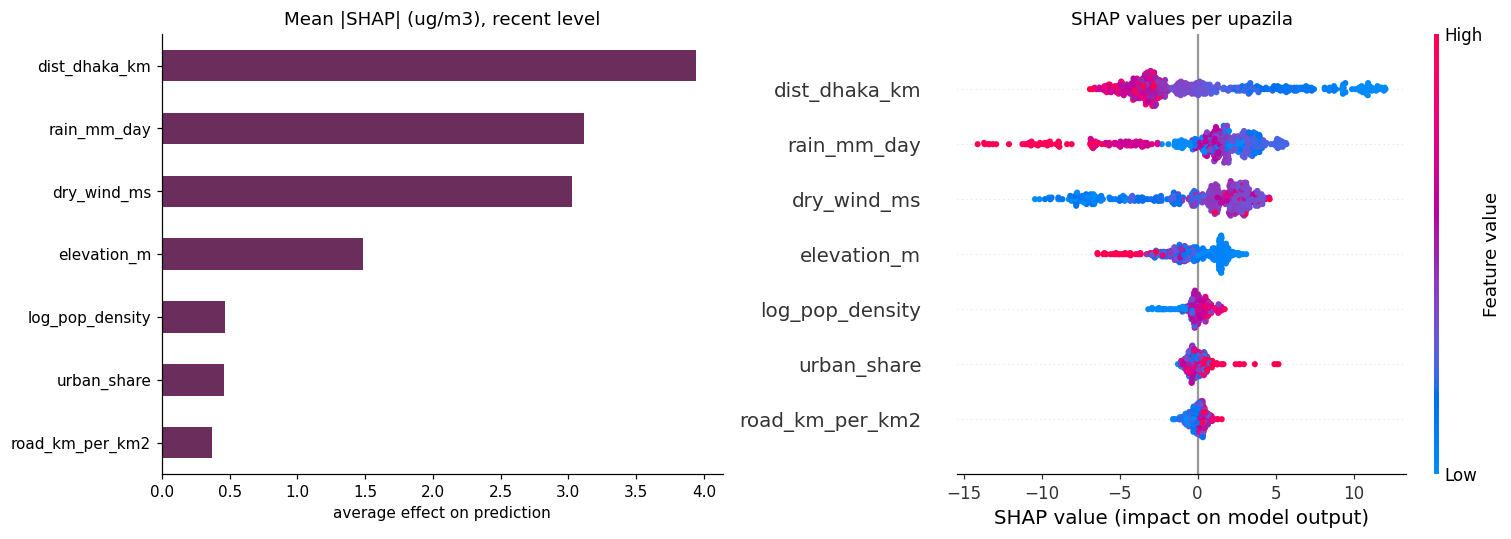

In [10]:
xgb = models["XGBoost"].fit(X, df["pm25_recent"])
explainer = shap.TreeExplainer(xgb)
sv = explainer(X)
pd.DataFrame(sv.values, columns=FEATURES).assign(pcode=df["pcode"].values).to_csv(MOD / "05_shap_values.csv", index=False)
importance = pd.Series(np.abs(sv.values).mean(0), index=FEATURES).sort_values()
fig = plt.figure(figsize=(14, 5))
ax1 = fig.add_subplot(1, 2, 1); importance.plot.barh(ax=ax1, color=PLUM); ax1.set(title="Mean |SHAP| (ug/m3), recent level", xlabel="average effect on prediction")
ax2 = fig.add_subplot(1, 2, 2); shap.plots.beeswarm(sv, max_display=len(FEATURES), show=False, plot_size=None, ax=ax2); ax2.set_title("SHAP values per upazila")
plt.tight_layout(); plt.savefig(FIG / "05_shap_recent.png", dpi=200, bbox_inches="tight")
importance.sort_values(ascending=False).round(2).rename("mean_abs_shap")

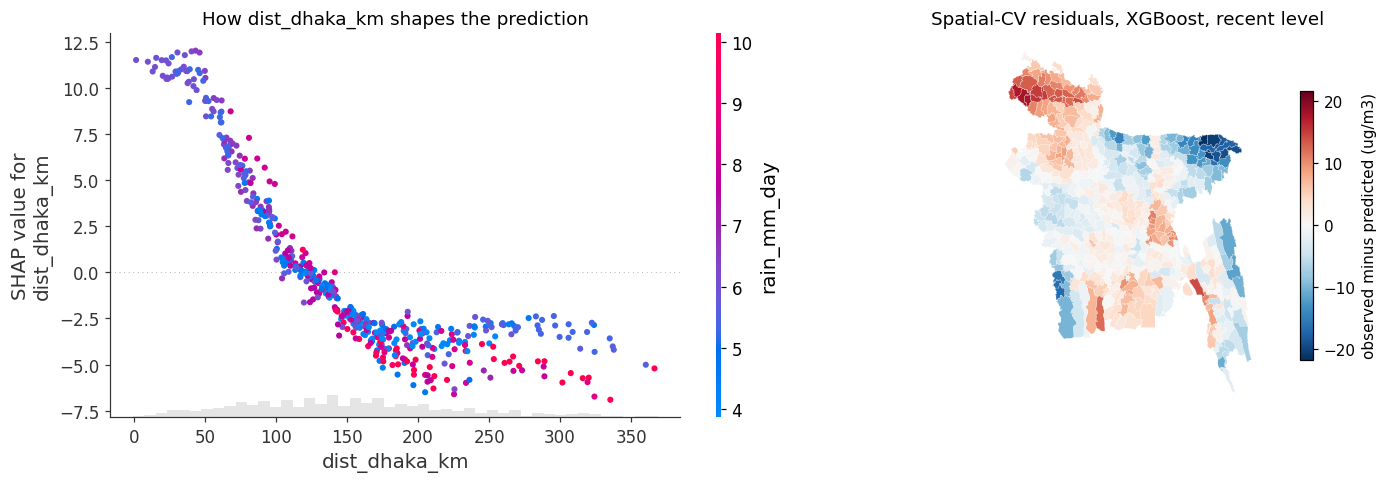

In [11]:
top = importance.index[-1]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
shap.plots.scatter(sv[:, top], color=sv, ax=ax[0], show=False); ax[0].set_title(f"How {top} shapes the prediction")
res = df["pm25_recent"] - oof["pm25_recent|spatial|XGBoost"]
upazila.assign(res=res.values).plot(column="res", cmap="RdBu_r", vmin=-res.abs().max(), vmax=res.abs().max(), legend=True, legend_kwds={"label": "observed minus predicted (ug/m3)", "shrink": 0.7}, ax=ax[1], edgecolor="white", linewidth=0.1)
ax[1].set_title("Spatial-CV residuals, XGBoost, recent level"); ax[1].set_axis_off()
plt.tight_layout(); plt.savefig(FIG / "05_shap_top_and_residuals.png", dpi=200, bbox_inches="tight")

**Residual map:** if the residuals form patches of red and blue rather than salt and pepper, the covariates leave out something spatial (such as brick kiln clusters or smoke drifting across the border). That is exactly what the spatial lag and spatial error models in R script 08 are built for, and why the covariate table is saved for them.

## Summary

In [12]:
best = cv_results.query("cv == 'spatial'").sort_values("R2", ascending=False).groupby("target").head(1)
drop = cv_results.pivot_table(index=["target", "model"], columns="cv", values="R2").assign(drop=lambda d: d["random"] - d["spatial"]).round(3)
print("Best model under spatial CV:"); print(best[["target", "model", "R2", "MAE"]].to_string(index=False))
print("\nTop three SHAP drivers (recent level):", ", ".join(importance.sort_values(ascending=False).index[:3]))
drop

Best model under spatial CV:
     target   model    R2   MAE
pm25_recent XGBoost 0.660 4.713
pm25_change XGBoost 0.404 2.490

Top three SHAP drivers (recent level): dist_dhaka_km, rain_mm_day, dry_wind_ms


cv                             random  spatial   drop
target      model                                    
pm25_change Linear regression   0.586    0.356  0.230
            Random forest       0.816    0.347  0.469
            XGBoost             0.834    0.404  0.430
pm25_recent Linear regression   0.640    0.279  0.361
            Random forest       0.925    0.619  0.306
            XGBoost             0.938    0.660  0.278

## Next: R scripts 06 to 10 in RStudio

Copy the Drive project folder to the laptop (`E:\Bangladesh Air Pollution Project`) once, then run the R scripts: 06 trends and seasonality (Mann-Kendall, Sen's slope, STL), 07 spatial autocorrelation (Moran's I, LISA, Gi*), 08 spatial regression on `upazila_covariates.parquet`, 09 WHO exposure bands, 10 Power BI export.